In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv


# Análise de Sentimento – Avaliações Olist

**Objetivo:** construir um modelo que classifica avaliações de clientes de e-commerce brasileiro como **positivas** ou **negativas**.

**Dataset:** Brazilian E-Commerce Public Dataset by Olist (avaliações reais, em português).

**Etapas:**
1. Análise exploratória dos dados
2. Baseline com TF-IDF + Regressão Logística
3. Fine-tuning do BERTimbau

In [3]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv")
print(df.shape)   # (linhas, colunas)
df.head()

(99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [4]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

<Axes: title={'center': 'Distribuição das notas'}, xlabel='review_score'>

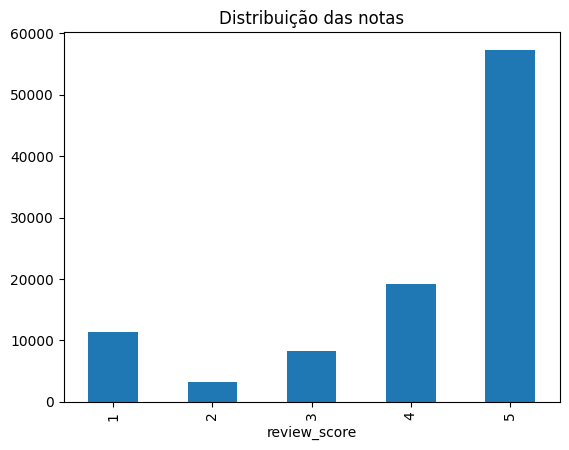

In [5]:
df["review_score"].value_counts().sort_index().plot(kind="bar", title="Distribuição das notas")

In [6]:
# só avaliações com comentário escrito
dados = df.dropna(subset=["review_comment_message"]).copy()

# remove nota 3 (neutra) e cria o rótulo
dados = dados[dados["review_score"] != 3]
dados["sentimento"] = (dados["review_score"] >= 4).astype(int)  # 1 = positivo, 0 = negativo

dados = dados[["review_comment_message", "review_score", "sentimento"]]
print(dados.shape)
print(dados["sentimento"].value_counts(normalize=True))

(37420, 3)
sentimento
1    0.708979
0    0.291021
Name: proportion, dtype: float64


## Conclusões da análise exploratória

- O dataset tem **99.224 avaliações**, mas apenas **40.977 (~41%) têm comentário escrito**. Só essas servem para treinar um modelo de texto.
- O título do comentário quase nunca é preenchido (~12%), então foi descartado.
- As notas são **muito desbalanceadas**: a nota 5 representa mais da metade das avaliações. Há mais notas 1 do que 2, o que sugere que clientes insatisfeitos tendem a ir direto ao extremo.
- Removi a **nota 3** por ser ambígua e defini: notas 1–2 = **negativo (0)**, notas 4–5 = **positivo (1)**.
- Resultado: **37.420 avaliações**, sendo **70,9% positivas e 29,1% negativas**.

**Implicação:** um modelo que sempre previsse "positivo" teria ~71% de accuracy sem aprender nada. Por isso, vou avaliar os modelos pelo **F1-score** e pelo **recall da classe negativa**, que é a mais importante para identificar clientes insatisfeitos.

In [7]:
from sklearn.model_selection import train_test_split

X = dados["review_comment_message"]   # entrada: o texto
y = dados["sentimento"]               # resposta certa: 0 ou 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(len(X_train), "treino |", len(X_test), "teste")

29936 treino | 7484 teste


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

dummy = DummyClassifier(strategy="most_frequent").fit(X_train.to_frame(), y_train)
print(classification_report(y_test, dummy.predict(X_test.to_frame()),
      target_names=["negativo", "positivo"], zero_division=0))

              precision    recall  f1-score   support

    negativo       0.00      0.00      0.00      2178
    positivo       0.71      1.00      0.83      5306

    accuracy                           0.71      7484
   macro avg       0.35      0.50      0.41      7484
weighted avg       0.50      0.71      0.59      7484



In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

modelo = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, strip_accents="unicode"),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["negativo", "positivo"], digits=3))

              precision    recall  f1-score   support

    negativo      0.825     0.948     0.882      2178
    positivo      0.977     0.917     0.946      5306

    accuracy                          0.926      7484
   macro avg      0.901     0.932     0.914      7484
weighted avg      0.933     0.926     0.928      7484



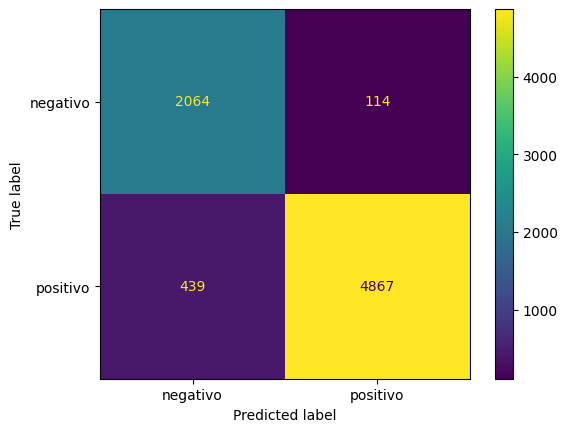

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["negativo", "positivo"])

In [11]:
import numpy as np

vec = modelo.named_steps["tfidfvectorizer"]
clf = modelo.named_steps["logisticregression"]
palavras = np.array(vec.get_feature_names_out())
ordem = np.argsort(clf.coef_[0])

print("Mais negativas:", palavras[ordem[:15]])
print("Mais positivas:", palavras[ordem[-15:]])

Mais negativas: ['nao' 'comprei' 'nao recomendo' 'nao recebi' 'pessima' 'nem' 'pessimo'
 'ruim' 'diferente' 'quero' 'veio' 'demora' 'nao gostei' 'nao chegou'
 'produto nao']
Mais positivas: ['antes do' 'otima' 'bem' 'otimo' 'perfeito' 'lindo' 'amei' 'rapido'
 'adorei' 'parabens' 'rapida' 'tudo' 'antes' 'recomendo' 'excelente']


In [12]:
frases = [
    "Chegou antes do prazo, adorei!",
    "Produto veio quebrado e ninguém responde",
    "Não recomendo",
    "Não é ruim, até que gostei",
]
for frase, p in zip(frases, modelo.predict_proba(frases)[:, 1]):
    print(f"{p:.0%} positivo → {frase}")

100% positivo → Chegou antes do prazo, adorei!
8% positivo → Produto veio quebrado e ninguém responde
1% positivo → Não recomendo
4% positivo → Não é ruim, até que gostei


In [13]:
teste = pd.DataFrame({"texto": X_test, "real": y_test, "previsto": y_pred})
erros = teste[teste["real"] != teste["previsto"]]
print(len(erros), "erros")
erros.sample(10, random_state=1)

553 erros


,texto,real,previsto
85399,Nota 10\r\n,0,1
51553,Eu tinha pedido o cancelamento mais não precis...,1,0
15171,"Tudo certo com a loja, mas 1 mês esperando os ...",0,1
73162,A semana toda ligando e nada de resolver meu p...,1,0
72248,Um dos relogios viram com defeito preciso faze...,1,0
14674,Apesar de ter recebido com uma rodinha quebrad...,1,0
9661,"o relógio é bonito, porém não é para o dia a d...",1,0
72154,"Só há fatos positivos, não houve transtornos.",1,0
8394,Comprei duas redes que na descrição dizia que ...,1,0
45728,Gostei muito,0,1


## Conclusões do baseline (TF-IDF + Regressão Logística)

| Modelo | Accuracy | F1 negativo | F1 macro |
|---|---|---|---|
| Sempre "positivo" | 0,71 | 0,00 | 0,41 |
| **TF-IDF + Reg. Logística** | **0,926** | **0,882** | **0,914** |

- Com `class_weight="balanced"`, o modelo atinge **recall de 94,8% nos negativos**, deixando escapar poucos clientes insatisfeitos, com precision de 82,5%. Para o negócio, essa troca é desejável: um alarme falso custa menos que um cliente insatisfeito ignorado.
- As palavras mais relevantes mostram que **prazo de entrega** é o principal fator de satisfação ("antes do prazo" × "não chegou").
- **Análise de erros:**
  - Parte dos erros é **ruído nos rótulos** (ex.: "Gostei muito" com nota baixa).
  - Outra parte é **limitação do modelo**: por tratar o texto como um "saco de palavras", ele falha em **negações e contrastes** ("não houve transtornos", "apesar de…").
- **Próximo passo:** fazer fine-tuning de um Transformer (BERTimbau), que considera o contexto da frase inteira e deve tratar melhor esses casos.

# Fine-tuning do BERTimbau
O baseline falha em negações e contrastes ("não houve transtornos") por tratar o texto como um saco de palavras. Aqui faço o fine-tuning do **BERTimbau**, um Transformer pré-treinado em português que considera o contexto da frase inteira.

In [14]:
# Separa 10% do treino para validação (usada para escolher a melhor época)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)
print(len(X_tr), "treino |", len(X_val), "validação |", len(X_test), "teste")

26942 treino | 2994 validação | 7484 teste


In [15]:
from transformers import AutoTokenizer
from datasets import Dataset

MODELO_BASE = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

def criar_dataset(X, y):
    return Dataset.from_dict({"texto": list(X), "label": list(y)})

def tokenizar(batch):
    return tokenizer(batch["texto"], truncation=True, max_length=128)

train_ds = criar_dataset(X_tr, y_tr).map(tokenizar, batched=True)
val_ds   = criar_dataset(X_val, y_val).map(tokenizar, batched=True)
test_ds  = criar_dataset(X_test, y_test).map(tokenizar, batched=True)

print(tokenizer.tokenize("Não é ruim, até que gostei"))

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/26942 [00:00<?, ? examples/s]

Map:   0%|          | 0/2994 [00:00<?, ? examples/s]

Map:   0%|          | 0/7484 [00:00<?, ? examples/s]

['Não', 'é', 'ruim', ',', 'até', 'que', 'gos', '##te', '##i']


In [16]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=2,
    id2label={0: "negativo", 1: "positivo"},
    label2id={"negativo": 0, "positivo": 1},
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

In [17]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, recall_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "f1_negativo": f1_score(labels, preds, pos_label=0),
        "recall_negativo": recall_score(labels, preds, pos_label=0),
    }

In [18]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding, EarlyStoppingCallback

args = TrainingArguments(
    output_dir="bertimbau-olist",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    fp16=True,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)

trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Negativo,Recall Negativo
1,No log,0.306411,0.950568,0.940956,0.917133,0.940299
2,0.346119,0.332480,0.951570,0.942538,0.919757,0.954076
3,0.220660,0.334554,0.954242,0.945327,0.923249,0.946039


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1263, training_loss=0.2622758619198229, metrics={'train_runtime': 598.2788, 'train_samples_per_second': 135.098, 'train_steps_per_second': 2.111, 'total_flos': 2825282401345440.0, 'train_loss': 0.2622758619198229, 'epoch': 3.0})

In [19]:
# Salva o modelo no Hugging Face logo após o treino
from kaggle_secrets import UserSecretsClient
hf_token = UserSecretsClient().get_secret("HF_TOKEN")

NOME_REPO = "VictorHGomes/bertimbau-sentimento-olist"  

trainer.model.push_to_hub(NOME_REPO, token=hf_token)
tokenizer.push_to_hub(NOME_REPO, token=hf_token)
print("Publicado em: https://huggingface.co/" + NOME_REPO)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Publicado em: https://huggingface.co/VictorHGomes/bertimbau-sentimento-olist


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

    negativo      0.899     0.924     0.911      2178
    positivo      0.969     0.957     0.963      5306

    accuracy                          0.948      7484
   macro avg      0.934     0.941     0.937      7484
weighted avg      0.948     0.948     0.948      7484



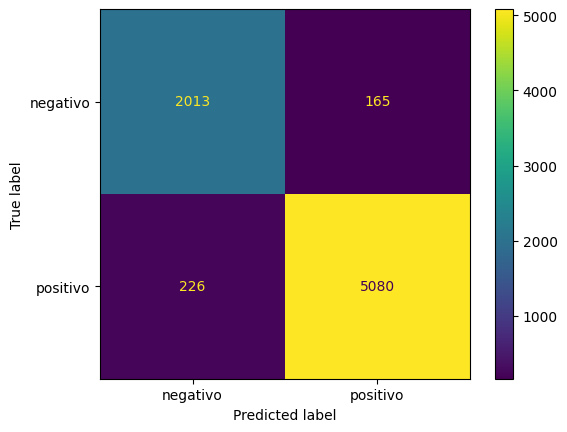

In [20]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred = trainer.predict(test_ds)
y_pred_bert = np.argmax(pred.predictions, axis=-1)

print(classification_report(y_test, y_pred_bert, target_names=["negativo", "positivo"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bert, display_labels=["negativo", "positivo"])

In [21]:
from transformers import pipeline

clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, device=0)
for frase in frases + ["Só há fatos positivos, não houve transtornos."]:
    r = clf(frase)[0]
    print(f"{r['label']:>9} ({r['score']:.0%}) → {frase}")

 positivo (100%) → Chegou antes do prazo, adorei!
 negativo (99%) → Produto veio quebrado e ninguém responde
 negativo (99%) → Não recomendo
 positivo (89%) → Não é ruim, até que gostei
 positivo (98%) → Só há fatos positivos, não houve transtornos.


In [22]:
comp = pd.DataFrame({"texto": X_test, "real": y_test, "baseline": y_pred, "bert": y_pred_bert})
corrigidos = comp[(comp["baseline"] != comp["real"]) & (comp["bert"] == comp["real"])]
pioraram   = comp[(comp["baseline"] == comp["real"]) & (comp["bert"] != comp["real"])]
print(len(corrigidos), "erros do baseline corrigidos pelo BERT")
print(len(pioraram), "acertos do baseline que o BERT errou")
corrigidos.sample(10, random_state=1)

286 erros do baseline corrigidos pelo BERT
124 acertos do baseline que o BERT errou


,texto,real,baseline,bert
79984,Ainda nao utilizei motivo pelo qual nao posso ...,1,0,1
39299,Deveria ser entregue todos os produtos de uma ...,1,0,1
72118,Mais rápido que o imaginado. \r\nNão tem fresc...,1,0,1
56694,Hidrata bem porém não alisa muito,1,0,1
1217,só acho que poderia ter comprado mais cartucho...,1,0,1
34078,Capinha de material bom e a proteção de tela e...,1,0,1
84062,Apesar de a foto do produto ser diferente do e...,1,0,1
66102,"comprem, mas o frete e muito caro, poderia ser...",1,0,1
43035,"Tudo chegou certinho, só esperava que o massag...",1,0,1
67247,atrasou muito,0,1,0


## Conclusões: Baseline × BERTimbau

| Modelo | Accuracy | F1 negativo | Precision neg. | Recall neg. | F1 macro | Erros |
|---|---|---|---|---|---|---|
| Sempre "positivo" | 0,710 | 0,000 | 0,000 | 0,000 | 0,410 | — |
| TF-IDF + Reg. Logística | 0,926 | 0,882 | 0,825 | 0,948 | 0,914 | 553 |
| **BERTimbau (fine-tuning)** | **0,948** | **0,911** | **0,899** | 0,924 | **0,937** | **391** |

- O BERTimbau **reduziu os erros em 29%** (553 → 391) e superou o baseline em todas as métricas, exceto o recall negativo.
- **Trade-off:** o baseline (com `class_weight="balanced"`) prioriza recall e gera o dobro de alarmes falsos (439 × 226). O BERT é mais equilibrado. Se o negócio exigir recall máximo, é possível ajustar o limiar de decisão.
- **Hipótese confirmada:** o BERT corrigiu 286 erros do baseline, principalmente frases com **contrastes** ("porém", "apesar de", "mas") e **negações** ("não houve transtornos"), graças ao mecanismo de atenção, que considera o contexto da frase inteira.
- **Custo × benefício:** o baseline treina em segundos, sem GPU; o BERT levou ~10 min em GPU e é mais pesado para servir. O ganho de +2,3 pts em F1 macro e −29% de erros justifica o custo quando a qualidade importa; para triagem em larga escala com orçamento apertado, o baseline continua competitivo.
- **Modelo publicado:** [huggingface.co/VictorHGomes/bertimbau-sentimento-olist](https://huggingface.co/VictorHGomes/bertimbau-sentimento-olist)